<a href="https://colab.research.google.com/github/pstrings/MachineLearningTraining/blob/main/ML_Algorithms.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Linear Regression

In [2]:
def standardize_x(X):
  X_mean = X.mean()
  X_std = X.std()

  return (X - X_mean) / X_std

In [3]:
def linear_regression_gd(X, y, learning_rate, iterations):

  losses = []
  # Initial parameters
  w = b = 0.0

  for _ in range(iterations):
    y_pred = w * X + b

    # Calculation of mse
    mse = np.mean((y_pred - y) ** 2)
    losses.append(mse)

    # Calculate gradients
    dw = 2 * np.mean((y_pred - y) * X)
    db = 2 * np.mean(y_pred - y)

    # Update parameters
    w -= learning_rate * dw
    b -= learning_rate * db

  final_pred = w * X + b
  losses.append(np.mean((final_pred - y) ** 2))

  return w, b, losses

In [5]:
X = np.array([50, 70, 90, 110], dtype=float)
y = np.array([27, 34, 48, 51], dtype=float)

learning_rates = [0.001, 0.1, 1.1]
results = {}

X_scaled = standardize_x(X)

for lr in learning_rates:
  w, b, losses = linear_regression_gd(X_scaled, y, learning_rate=lr, iterations=100)

  results[lr] = losses

  print(
      f"LR={lr}: final MSE = {losses[-1]:.6f}, weight = {w:.4f}, bias = {b:.4f}"
  )

LR=0.001: final MSE = 1139.078854, weight = 1.7445, bias = 7.2573
LR=0.1: final MSE = 5.050000, weight = 9.6151, bias = 40.0000
LR=1.1: final MSE = 11608204669055033344.000000, weight = -796302459.7822, bias = -3312718940.8806


## Plotting loss curves

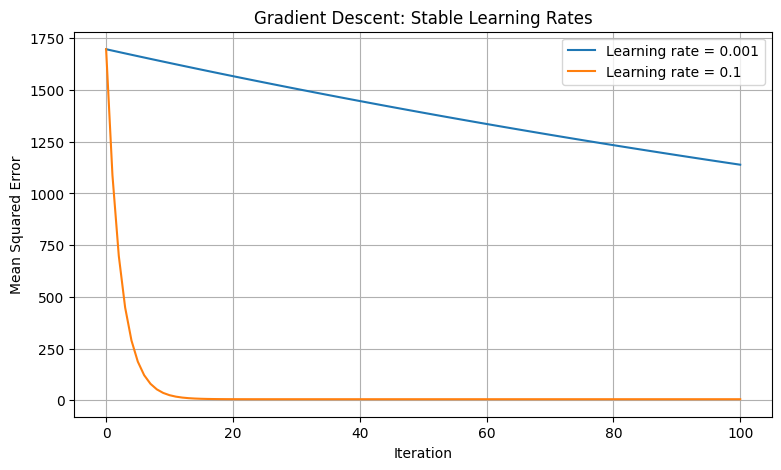

In [7]:
plt.figure(figsize=(9, 5))

for lr in [0.001, 0.1]:
  plt.plot(results[lr], label=f"Learning rate = {lr}")

plt.xlabel("Iteration")
plt.ylabel("Mean Squared Error")
plt.title("Gradient Descent: Stable Learning Rates")
plt.legend()
plt.grid(True)
plt.show()

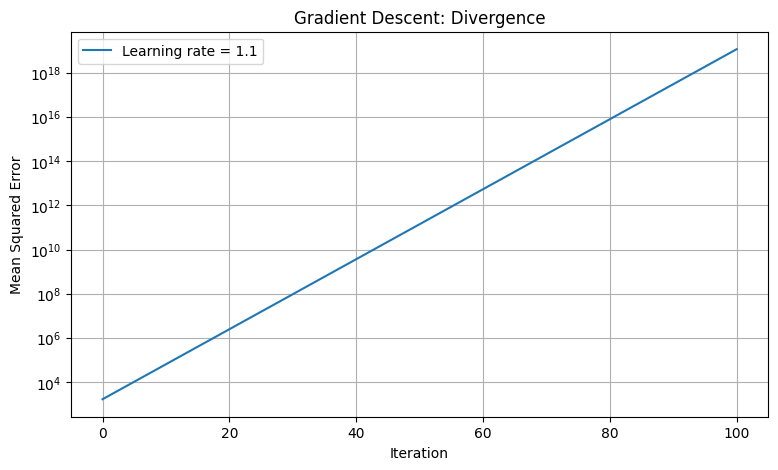

In [8]:
plt.figure(figsize=(9, 5))

plt.plot(results[1.1], label="Learning rate = 1.1")

plt.xlabel("Iteration")
plt.ylabel("Mean Squared Error")
plt.title("Gradient Descent: Divergence")
plt.yscale("log")
plt.legend()
plt.grid(True)
plt.show()